In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt, seaborn as sns
from ss_utils import *
df = load_data(".")   # the folder with train.csv and test.csv

In [2]:
from scipy.stats import ttest_rel
IMPUTE, GROUPS = "logic", ("G1", "G2", "G3", "G4")      # same as 04_models
X, y, g, X_te, ids, _ = build(df, impute=IMPUTE, groups=GROUPS)

oof   = pd.read_csv("results/oof.csv")
p_cat = oof["cat"].to_numpy()                                        # CatBoost default
p_pfn = pd.read_csv("results/tabpfn_oof.csv")["tabpfn_oof"].to_numpy()
p_fin = (p_pfn + p_cat) / 2                                          # final blend

FOLDS0 = [va for _, va in get_folds(y, g, "group", seed=0)]           # the 5 folds TabPFN used
def score(p):
    f = np.array([accuracy_score(y[va], p[va] > 0.5) for va in FOLDS0])
    return {"mean": f.mean(), "std": f.std(), "folds": f,
            "oof_acc": accuracy_score(y, p > 0.5), "seconds": 0}

res = {"CatBoost default": score(p_cat), "TabPFN": score(p_pfn), "Blend 50/50": score(p_fin)}
table_final = pd.DataFrame([{"Model": k, "CV acc (5 folds)": round(r["mean"], 4), "± std": round(r["std"], 4)}
                            for k, r in res.items()])
table_final.to_latex("results/e5_final_candidates.tex", index=False); display(table_final)
paired_test(res["CatBoost default"], res["Blend 50/50"], "CatBoost", "blend")
paired_test(res["TabPFN"], res["Blend 50/50"], "TabPFN", "blend")

,Model,CV acc (5 folds),± std
0,CatBoost default,0.8169,0.0044
1,TabPFN,0.8171,0.0036
2,Blend 50/50,0.8201,0.0061


blend - CatBoost: +0.0032 accuracy (better on 4/5 folds), p = 0.104
blend - TabPFN: +0.0030 accuracy (better on 3/5 folds), p = 0.282


(0.0029953166299167, 0.2816101155490329)

In [3]:
log = pd.read_csv(LOG_PATH)
new = [("E4-tabpfn", "E4 models", "TabPFN (Colab T4), seed-0 folds", "tabpfn", res["TabPFN"]),
       ("E5-tabpfn-cat", "E5 ensembles", "50/50 TabPFN + CatBoost default, seed-0 folds", "ensemble", res["Blend 50/50"])]
for rid, exp, desc, model, r in new:
    if rid not in set(log.run_id):
        log_result(rid, exp, desc, model, r)

LB = {"B0": 0.79424, "E3-group": 0.80710, "E3-plain": 0.80710, "E4-cat-default": 0.80757,
      "E4-tabpfn": 0.81295, "E5-tabpfn-cat": 0.81248,
      "E4-cat-tuned": 0.80406, "E5-avg3": 0.80453, "E5-cat2": 0.80406, "E4-cat-tuned3": 0.80500}  
log = pd.read_csv(LOG_PATH)
for rid, s in LB.items():
    if s is not None:
        log.loc[log.run_id == rid, "lb_score"] = s
log.to_csv(LOG_PATH, index=False)
log.dropna(subset=["lb_score"])[["run_id", "cv_mean", "lb_score"]]

,run_id,cv_mean,lb_score
0,B0,0.79562,0.79424
17,E3-group,0.81273,0.80710
18,E3-plain,0.81468,0.80710
24,E4-cat-default,0.81491,0.80757
27,E4-cat-tuned,0.81503,0.80406
28,E5-avg3,0.81480,0.80453
29,E5-cat2,0.81617,0.80406
30,E4-cat-tuned3,0.81591,0.80500
31,E4-tabpfn,0.81710,0.81295
32,E5-tabpfn-cat,0.82009,0.81248


,Passengers where the models disagree,CatBoost right,TabPFN right,Blend right
0,478,238,240,266


correlation of probabilities: 0.981


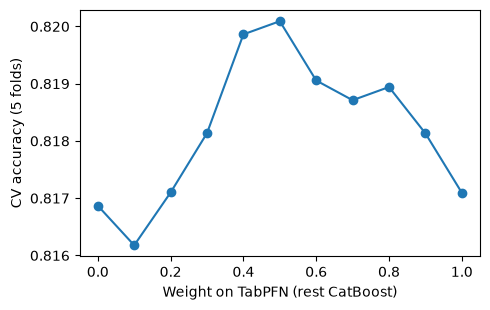

In [4]:
a, b, f = p_cat > 0.5, p_pfn > 0.5, p_fin > 0.5
dis = a != b
agree = pd.DataFrame([{"Passengers where the models disagree": int(dis.sum()),
                       "CatBoost right": int((a[dis] == y[dis]).sum()),
                       "TabPFN right": int((b[dis] == y[dis]).sum()),
                       "Blend right": int((f[dis] == y[dis]).sum())}])
agree.to_latex("results/e5_disagreement.tex", index=False); display(agree)
print("correlation of probabilities:", np.corrcoef(p_pfn, p_cat)[0, 1].round(3))

w = np.round(np.arange(0, 1.01, 0.1), 1)
cv_w = [score(wi * p_pfn + (1 - wi) * p_cat)["mean"] for wi in w]
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(w, cv_w, "o-")
ax.set_xlabel("Weight on TabPFN (rest CatBoost)"); ax.set_ylabel("CV accuracy (5 folds)")
plt.tight_layout(); plt.savefig("figures/fig_blend_weight.png", dpi=200); plt.show()

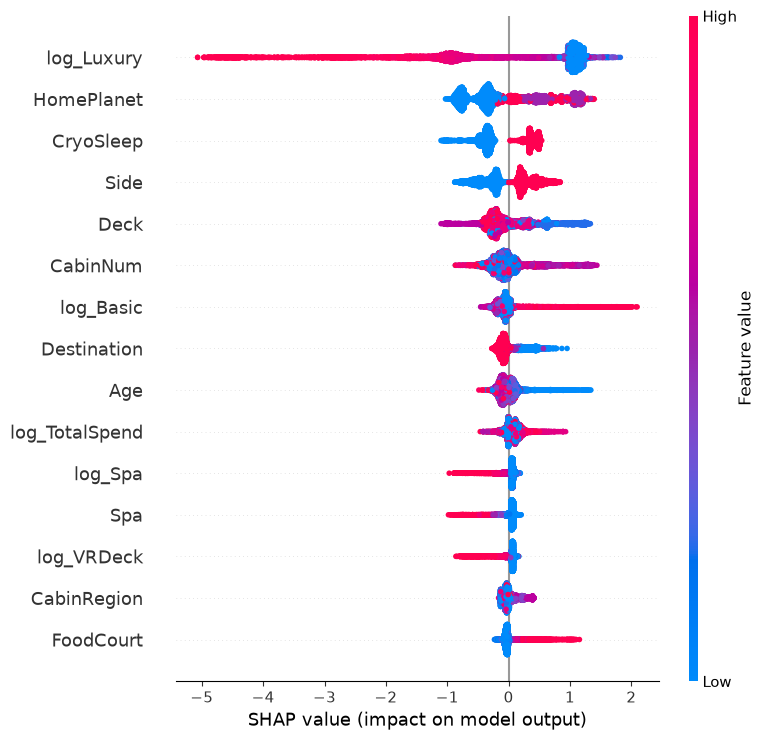

log_Luxury        1.218173
HomePlanet        0.553602
CryoSleep         0.385048
Side              0.341367
Deck              0.324724
CabinNum          0.227712
log_Basic         0.177789
Destination       0.149052
Age               0.117384
log_TotalSpend    0.114317
log_Spa           0.104389
Spa               0.100738
log_VRDeck        0.094382
CabinRegion       0.079473
FoodCourt         0.065842
dtype: float64

In [5]:
import shap
from catboost import CatBoostClassifier, Pool
cats = [c for c in X.columns if str(X[c].dtype) == "category"]
Xc, _ = prepare(X, None, "cat")
m = CatBoostClassifier(random_seed=0, verbose=0, cat_features=cats).fit(Xc, y)
sv = m.get_feature_importance(Pool(Xc, y, cat_features=cats), type="ShapValues")[:, :-1]   # last column = base value
X_plot = X.apply(lambda c: c.cat.codes if str(c.dtype) == "category" else c)
shap.summary_plot(sv, X_plot, max_display=15, show=False)
plt.savefig("figures/fig_shap_summary.png", dpi=200, bbox_inches="tight"); plt.show()
imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
imp.head(15).round(4).to_frame("mean |SHAP|").to_latex("results/e6_shap_top15.tex"); imp.head(15)

In [6]:
th = pd.DataFrame({"threshold": np.round(np.arange(0.40, 0.61, 0.02), 2)})
th["OOF accuracy"] = [accuracy_score(y, p_fin > t) for t in th.threshold]
th.to_latex("results/e7_threshold.tex", index=False); th.round(4)

,threshold,OOF accuracy
0,0.40,0.8151
1,0.42,0.8163
2,0.44,0.8182
3,0.46,0.8189
4,0.48,0.8196
5,0.50,0.8201
6,0.52,0.8185
7,0.54,0.8192
8,0.56,0.8192
9,0.58,0.8143


In [7]:
def run_cv_pseudo(model, X, y, groups, X_te, params=None, conf=0.95, seeds=(0, 1, 2)):
    Xp, Xtp = prepare(X, X_te, model)
    cat_cols = [c for c in X.columns if str(X[c].dtype) == "category"] if model == "cat" else None
    scores = []
    for s in seeds:
        for tr_i, va_i in get_folds(y, groups, "group", seed=s):
            m = get_model(model, s, params, cat_cols); m.fit(Xp.iloc[tr_i], y[tr_i])
            pt = m.predict_proba(Xtp)[:, 1]
            keep = (pt > conf) | (pt < 1 - conf)
            X_aug = pd.concat([Xp.iloc[tr_i], Xtp[keep]], ignore_index=True)
            y_aug = np.concatenate([y[tr_i], (pt[keep] > 0.5).astype(int)])
            m2 = get_model(model, s, params, cat_cols); m2.fit(X_aug, y_aug)
            scores.append(accuracy_score(y[va_i], m2.predict_proba(Xp.iloc[va_i])[:, 1] > 0.5))
    print(f"pseudo-labelled ({keep.sum()} test rows added): {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return {"mean": float(np.mean(scores)), "std": float(np.std(scores)),
            "folds": np.array(scores), "oof_acc": np.nan, "seconds": 0}

base = run_cv("cat", X, y, g)
pl = run_cv_pseudo("cat", X, y, g, X_te)
paired_test(base, pl, "no pseudo-labels", "pseudo-labels")
log_result("E7-PL", "E7 tricks", "pseudo-labelling, conf 0.95", "cat", pl)

cat     CV acc = 0.8149 ± 0.0072  (oof 0.8169, 40.8s)
pseudo-labelled (1354 test rows added): 0.8146 ± 0.0070
pseudo-labels - no pseudo-labels: -0.0003 accuracy (better on 8/15 folds), p = 0.753


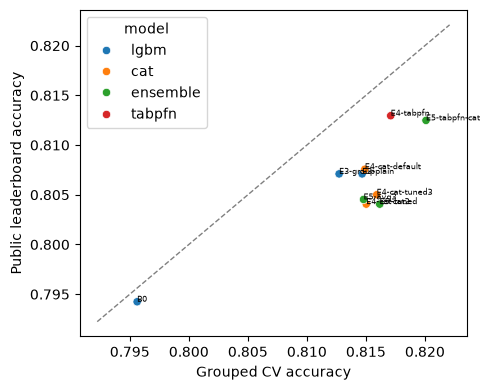

SignificanceResult(statistic=0.45122790065613705, pvalue=0.19054977390973094) n = 10


,A,B,Different predictions
0,B0_baseline_lgbm,E3_lgbm_fixed,403
1,B0_baseline_lgbm,E4_cat_default,441
2,B0_baseline_lgbm,E4_cat_tuned,432
3,B0_baseline_lgbm,E4_cat_tuned3_10seeds,420
4,B0_baseline_lgbm,E4_tabpfn,458
5,B0_baseline_lgbm,E5_avg3,434
6,B0_baseline_lgbm,E5_cat2_10seeds,428
7,B0_baseline_lgbm,E5_tabpfn_cat_blend,436
8,E3_lgbm_fixed,E4_cat_default,156
9,E3_lgbm_fixed,E4_cat_tuned,175


In [8]:
import itertools, os
from scipy.stats import spearmanr
log = pd.read_csv(LOG_PATH).dropna(subset=["lb_score"])
fig, ax = plt.subplots(figsize=(5, 4))
sns.scatterplot(data=log, x="cv_mean", y="lb_score", hue="model", ax=ax)
lo = log[["cv_mean", "lb_score"]].min().min() - 0.002
hi = log[["cv_mean", "lb_score"]].max().max() + 0.002
ax.plot([lo, hi], [lo, hi], "--", c="grey", lw=1)
for _, r in log.iterrows():
    ax.annotate(r.run_id, (r.cv_mean, r.lb_score), fontsize=6)
ax.set_xlabel("Grouped CV accuracy"); ax.set_ylabel("Public leaderboard accuracy")
plt.tight_layout(); plt.savefig("figures/fig_cv_vs_lb.png", dpi=200); plt.show()
print(spearmanr(log.cv_mean, log.lb_score), "n =", len(log))

subs = {f[:-4]: pd.read_csv(f"submissions/{f}").set_index("PassengerId")["Transported"]
        for f in sorted(os.listdir("submissions")) if f.endswith(".csv")}
diff = pd.DataFrame([{"A": a_, "B": b_, "Different predictions": int((subs[a_] != subs[b_]).sum())}
                     for a_, b_ in itertools.combinations(subs, 2)])
diff.to_latex("results/e8_submission_overlap.tex", index=False); diff

In [9]:
tr = df[df.split == "train"].reset_index(drop=True)          # raw values, same row order as X
err = tr.assign(p=p_fin, wrong=((p_fin > 0.5).astype(int) != y))
spend0 = err[SPEND].fillna(0).sum(axis=1) == 0
seg = {
    "All passengers": np.ones(len(err), bool),
    "CryoSleep = True": err.CryoSleep == 1,
    "Awake, spent something": (err.CryoSleep == 0) & ~spend0,
    "Awake, spent nothing": (err.CryoSleep == 0) & spend0,
    "CryoSleep missing": err.CryoSleep.isna(),
    "Any raw value missing": err[["HomePlanet","CryoSleep","Cabin","Destination","Age","VIP"] + SPEND].isna().any(axis=1),
    "Uncertain (0.4 < p < 0.6)": err.p.between(0.4, 0.6),
}
table_err = pd.DataFrame([{"Segment": k, "Passengers": int(v.sum()), "Error rate": round(err.wrong[v].mean(), 3)}
                          for k, v in seg.items()])
table_err.to_latex("results/error_analysis.tex", index=False); display(table_err)
err.groupby("Deck")["wrong"].mean().round(3)

,Segment,Passengers,Error rate
0,All passengers,8693,0.180
1,CryoSleep = True,3037,0.179
2,"Awake, spent something",4921,0.171
3,"Awake, spent nothing",518,0.276
4,CryoSleep missing,217,0.161
5,Any raw value missing,1929,0.189
6,Uncertain (0.4 < p < 0.6),1455,0.462


Deck
A    0.152
B    0.055
C    0.048
D    0.136
E    0.199
F    0.159
G    0.284
T    0.000
Name: wrong, dtype: float64